In [10]:
import os, random
from PIL import Image, ImageEnhance, ImageOps
import matplotlib.pyplot as plt

random.seed(42)
data_dir = "./data"                      # your 20 class folders
out_dir  = "./yolo_dataset"
TILE = 224
valid_ext = (".jpg", ".jpeg", ".png")

class_folders = sorted([f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))])

# Split the SOURCE images first, so no test image reuses a training photo
splits = {"train": {}, "val": {}, "test": {}}
for c, folder in enumerate(class_folders):
    files = sorted(f for f in os.listdir(os.path.join(data_dir, folder)) if f.lower().endswith(valid_ext))
    random.shuffle(files)
    n = len(files)
    splits["train"][c] = files[:int(0.7 * n)]
    splits["val"][c]   = files[int(0.7 * n):int(0.85 * n)]
    splits["test"][c]  = files[int(0.85 * n):]

def augment(img):
    if random.random() < 0.5:
        img = ImageOps.mirror(img)
    img = ImageEnhance.Brightness(img).enhance(random.uniform(0.7, 1.3))
    img = ImageEnhance.Contrast(img).enhance(random.uniform(0.7, 1.3))
    img = ImageEnhance.Color(img).enhance(random.uniform(0.7, 1.3))
    return img

def make_image(split):
    rows, cols = random.choice([(1, 2), (2, 1), (2, 2), (2, 3), (3, 2), (3, 3)])
    W, H = cols * TILE, rows * TILE
    canvas = Image.new("RGB", (W, H), (255, 255, 255))
    labels = []
    for r in range(rows):
        for col in range(cols):
            c = random.randrange(len(class_folders))
            f = random.choice(splits[split][c])
            img = Image.open(os.path.join(data_dir, class_folders[c], f)).convert("RGB")
            img = augment(img)
            size = int(TILE * random.uniform(0.6, 1.0))          # random scale
            img = img.resize((size, size))
            x0 = col * TILE + random.randint(0, TILE - size)        # random position in its cell
            y0 = r * TILE + random.randint(0, TILE - size)
            canvas.paste(img, (x0, y0))
            # YOLO label: class x_center y_center width height (all 0–1)
            labels.append(f"{c} {(x0 + size/2)/W:.6f} {(y0 + size/2)/H:.6f} {size/W:.6f} {size/H:.6f}")
    return canvas, labels

counts = {"train": 210, "val": 45, "test": 45}                     # 300 images in total
for split, n in counts.items():
    os.makedirs(f"{out_dir}/images/{split}", exist_ok=True)
    os.makedirs(f"{out_dir}/labels/{split}", exist_ok=True)
    for i in range(n):
        img, labels = make_image(split)
        img.save(f"{out_dir}/images/{split}/{split}_{i:04d}.jpg")
        with open(f"{out_dir}/labels/{split}/{split}_{i:04d}.txt", "w") as fh:
            fh.write("\n".join(labels))
print("Done")

Done


In [4]:
names = {i: f for i, f in enumerate(class_folders)}
with open(f"{out_dir}/data.yaml", "w") as fh:
    fh.write(f"path: {os.path.abspath(out_dir)}\ntrain: images/train\nval: images/val\ntest: images/test\n")
    fh.write("names:\n" + "".join(f"  {i}: {n.strip()}\n" for i, n in names.items()))

In [4]:
# pip install ultralytics
from ultralytics import YOLO

model = YOLO("yolov8n.pt")                 # small pretrained model; yolov8s.pt is more accurate but slower
results = model.train(
    data="./yolo_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    seed=42,
    device="mps",                          # Apple Silicon Mac; use 0 on a Colab GPU, "cpu" otherwise
)

New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.164 🚀 Python-3.11.15 torch-2.14.0 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, m

/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work

       1/50      4.29G     0.6646      3.885      1.045         20        640: 100% ━━━━━━━━━━━━ 14/14 1.3s/it 17.8s0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5it/s 1.3s3.5s
                   all         45        231          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work

       2/50      4.29G     0.3126      3.658     0.9076         11        640: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.2s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s2.4s
                   all         45        231     0.0149     0.0778      0.013      0.013

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...

      48/50      4.31G     0.1209     0.4707     0.8153          6        640: 100% ━━━━━━━━━━━━ 14/14 1.6it/s 8.7s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s2.4s
                   all         45        231      0.976      0.964      0.988      0.983

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      49/50      4.28G     0.1674     0.4926     0.8767         63        640: 0% ──────────── 0/14  0.7s

/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work

      49/50      4.29G      0.132     0.4856      0.836          8        640: 100% ━━━━━━━━━━━━ 14/14 1.6it/s 8.5s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s2.4s
                   all         45        231      0.976       0.97      0.988      0.983

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vishalgupta/venv_311/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work

      50/50      4.31G     0.1236     0.5186     0.8241          4        640: 100% ━━━━━━━━━━━━ 14/14 1.7it/s 8.5s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s2.4s
                   all         45        231      0.974       0.97      0.988      0.983

50 epochs completed in 0.149 hours.
Optimizer stripped from /Users/vishalgupta/image-classification-project/runs/detect/train/weights/last.pt, 6.3MB
Optimizer stripped from /Users/vishalgupta/image-classification-project/runs/detect/train/weights/best.pt, 6.3MB

Validating /Users/vishalgupta/image-classification-project/runs/detect/train/weights/best.pt...
Ultralytics 8.4.164 🚀 Python-3.11.15 torch-2.14.0 MPS (Apple M4)
Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s1.9s
                   all      

In [6]:
best = YOLO("runs/detect/train/weights/best.pt")
metrics = best.val(data="./yolo_dataset/data.yaml", split="test")
print("mAP50:", round(metrics.box.map50, 4), " mAP50-95:", round(metrics.box.map, 4))

Ultralytics 8.4.164 🚀 Python-3.11.15 torch-2.14.0 CPU (Apple M4)
Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 212.5±112.9 MB/s, size: 42.3 KB)
val: Scanning /Users/vishalgupta/image-classification-project/yolo_dataset/labels/test... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 6.1Kit/s 0.0s
val: New cache created: /Users/vishalgupta/image-classification-project/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.2it/s 1.3s0.8s
                   all         45        240      0.984      0.983      0.995      0.986
         images_OBJ000         10         12      0.992          1      0.995      0.995
         images_OBJ001         10         13          1      0.859      0.995      0.995
         images_OBJ002         11         13      0.919          1      0.995      0.995
         images_OBJ

In [7]:
results = best.predict("./yolo_dataset/images/test/test_0000.jpg", conf=0.25)

for box in results[0].boxes:
    cls_id = int(box.cls)
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    print(f"ID {cls_id:2d} ({best.names[cls_id]}), confidence {float(box.conf):.2f}, "
          f"box: ({x1:.0f}, {y1:.0f}) to ({x2:.0f}, {y2:.0f})")

results[0].save("detected.jpg")            # image with the boxes drawn on it


image 1/1 /Users/vishalgupta/image-classification-project/yolo_dataset/images/test/test_0000.jpg: 448x640 1 images_OBJ000, 1 images_OBJ004, 1 images_OBJ070, 1 images_OBJ108, 1 images_OBJ111, 1 images_OBJ529, 22.1ms
Speed: 0.9ms preprocess, 22.1ms inference, 0.6ms postprocess per image at shape (1, 3, 448, 640)
ID 15 (images_OBJ529), confidence 1.00, box: (456, 231) to (655, 432)
ID  8 (images_OBJ108), confidence 0.99, box: (30, 239) to (218, 429)
ID  9 (images_OBJ111), confidence 0.99, box: (450, 0) to (671, 224)
ID  7 (images_OBJ070), confidence 0.98, box: (277, 278) to (438, 448)
ID  0 (images_OBJ000), confidence 0.98, box: (265, 27) to (442, 204)
ID  3 (images_OBJ004), confidence 0.94, box: (24, 4) to (220, 205)


'detected.jpg'

In [5]:
import os, random
os.makedirs("demo_images", exist_ok=True)
for i in range(3):
    img, _ = make_image("test")
    img.save(f"demo_images/new_multi_{i}.jpg")

ID  8 images_OBJ108     conf 0.83  box (224,0) to (443,224)
ID 13 images_OBJ222     conf 0.26  box (0,0) to (222,224)


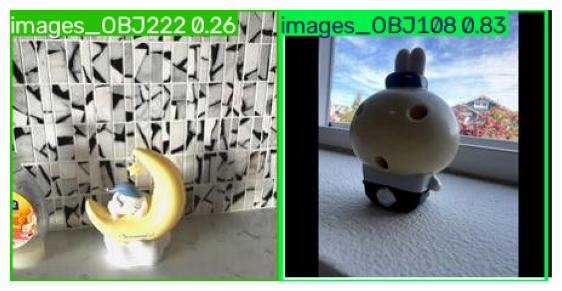

In [11]:
from ultralytics import YOLO

det = YOLO("runs/detect/train/weights/best.pt")

def detect(path):
    r = det.predict(path, conf=0.25, verbose=False)[0]
    for box in r.boxes:
        k = int(box.cls); x1, y1, x2, y2 = box.xyxy[0].tolist()
        print(f"ID {k:2d} {names[k]:<17} conf {float(box.conf):.2f}  box ({x1:.0f},{y1:.0f}) to ({x2:.0f},{y2:.0f})")
    plt.figure(figsize=(7, 7)); plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off"); plt.show()

detect("demo_images/new_multi_0.jpg")

ID  8 Usagi Toy         conf 0.83  box (224,0) to (443,224)
ID 13 Cinnamoroll Lamp  conf 0.26  box (0,0) to (222,224)


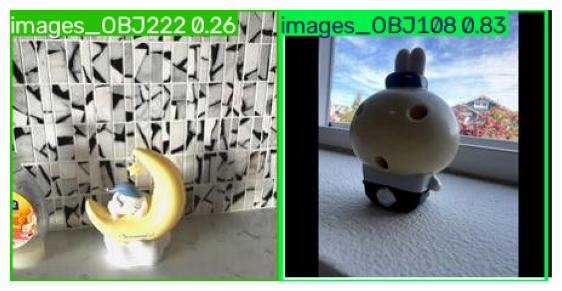

In [15]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

names = ["Globe", "Water Bottle", "Tissue", "Stop Sign", "Dog", "Car", "Coffee Mug", "Giraffe Figurine",
         "Usagi Toy", "Dragon", "Cat Plush", "Shoe", "Glasses", "Cinnamoroll Lamp", "Banana",
         "Garlic Jar", "Toothpaste", "Turkish Teapot", "Porto Wine", "Siberian Cat"]

det = YOLO("runs/detect/train/weights/best.pt")     # loads the saved model in about a second

def detect(path):
    r = det.predict(path, conf=0.25, verbose=False)[0]
    for box in r.boxes:
        k = int(box.cls); x1, y1, x2, y2 = box.xyxy[0].tolist()
        print(f"ID {k:2d} {names[k]:<17} conf {float(box.conf):.2f}  box ({x1:.0f},{y1:.0f}) to ({x2:.0f},{y2:.0f})")
    plt.figure(figsize=(7, 7)); plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off"); plt.show()

detect("demo_images/new_multi_0.jpg")